In [38]:
# TL;DR:

KMeans: fit, predict, inertia, centroids

```python
from sklearn.cluster import KMeans
model = KMeans(n_clusters = 3)
model.fit(samples)
labels = model.predict(samples)
model.fit_predict(samples) # why not both on same sample?
centroids = model.cluster_centers_ # x and y coordinates of centroids
inertia = model.inertia_ # lower = better

crosstab: "confusion matrix"
```python
import pandas as pd 
pd.crosstab(index = df['labels'], columns = df['varieties'])

# 1: Unsupervised learning

Unsupervised learning finds patterns in data ...  
but __without__ a specific prediction task in mind!



Datase: Iris  
- 3 species: Setosa, Versicolor, Virginica   
  
- 4 features: 
    - for each [Petal,Sepal]:
        - length,  width  



Iris data is 4-dimensional
- Columns are measurements (the __features__)
- Rows represent iris plants (the __samples__)

K-means clustering
- Finds clusters of samples
- Number of flusters must be specified

https://www.youtube.com/watch?v=4b5d3muPQmA
- clustering algorithm: aims to partition n observations into k clusters

```python
from sklearn.cluster import KMeans
model = KMeans(n_clusters = 3)
model.fit(samples)

labels = model.predict(samples)
print(labels)

new_labels = model.predict(new_samples)
print(new_labels)

import matplotlib.pyplot as plt
xs = samples[:,0]
ys = samples[:,2]
plt.scatter(xs, ys, c = labels)
plt.show()
```

cluster labels for new samples
- new samples can be assigned to existing clusters
- k-means remembers the mean of each cluster (the "centroids")
- finds the nearest centroid to each  new sample 

Time to practice!

f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


Text(0.5, 1.0, 'KNN: 3 clusters. Centroids: black "diamonds"')

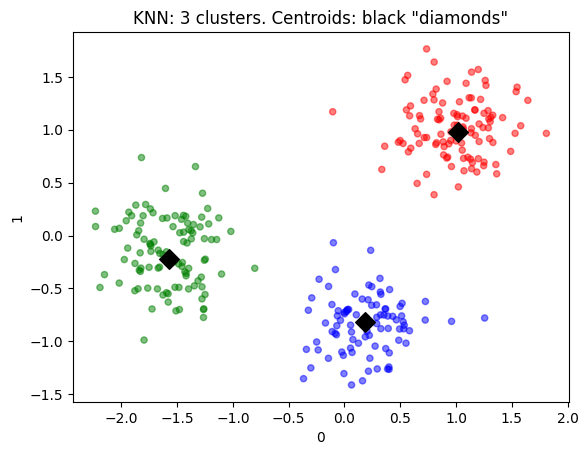

In [1]:
# import KMeans
from sklearn.cluster import KMeans 
import pandas as pd 
import matplotlib.pyplot as plt 
import numpy as np 

# Import dataset 
points = pd.read_csv('tables/points.csv')
new_points = pd.read_csv('tables/new_points.csv')

# Create a KMEans instance with 3 clusters: model
model = KMeans(n_clusters = 3)

# fit model to points
model.fit(points)

# Determine the cluser labels of new_points: labels
labels = model.predict(new_points)
dic = {0:'r', 1:'g', 2:'b'}

labels2 = [dic[k] for k in labels]
ax = new_points.plot.scatter(0,1, c = labels2, alpha = 0.5)

# Assign the cluster centers: centroids
centroids = model.cluster_centers_ 
pd.DataFrame(centroids).plot.scatter(0,1, ax = ax, marker = 'D', s = 100 , c = 'k')

plt.title('KNN: 3 clusters. Centroids: black "diamonds"')

Evaluating a cluster

- Check correspondence. Ex: Iris species - compare 3 species with KNN 3 clusters

```python
import pandas as pd 
df = pd.DataFrame({'labels': labels, 'species': species})
ct = pd.crosstab(df['labels'], df['species'])
```


Intertia measures clustering quality
- lower is better

```python
from sklearn import KMeans

model = KMeans(n_clusters = 3)
model.fit(samples)
print(model.inertia_)
```
- More clusters -> lower inertia

How many clusters to choose?
- choose the "elbow"

Let's pratice!

f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will c

Text(0.5, 1.0, 'seed length vs width, the KMeans groups and centroids')

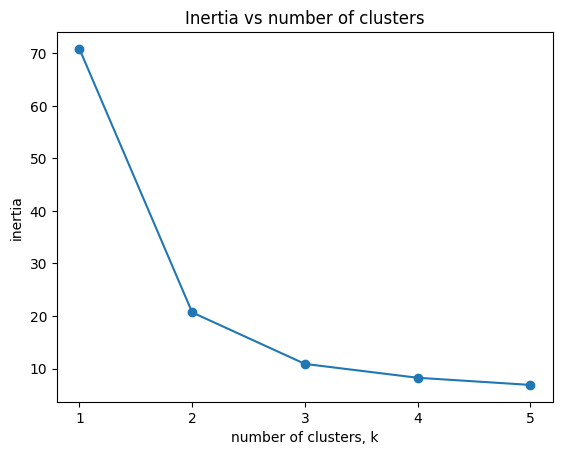

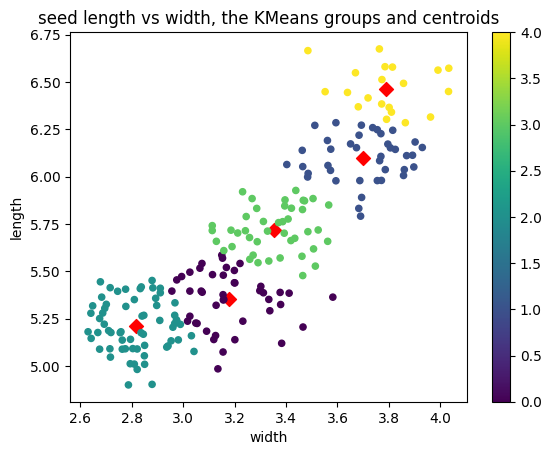

In [26]:
import pandas as pd 
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

ks = range(1,6)
inertias = []

samples = pd.read_csv('tables/seeds-width-vs-length.csv', header = None).set_axis(['width','length'], axis = 1)

for k in ks:
    # Create a KMeans instance with k clusters:
    model = KMeans(n_clusters = k)

    # Fit model to samples
    model.fit(samples)

    # append the inertia to the list of inertias
    inertias.append(model.inertia_)

# plot ks vs inertias
plt.plot(ks, inertias, '-o')
plt.xlabel('number of clusters, k')
plt.ylabel('inertia')
plt.xticks(ks)
plt.title('Inertia vs number of clusters')


## by sergio
centroids = model.cluster_centers_
ax = pd.DataFrame(centroids).plot.scatter(0,1, s = 50, marker = 'D', c= 'red')

samples.plot.scatter(x = 'width', y = 'length', c = model.predict(samples), cmap = 'viridis', ax = ax)
plt.title('seed length vs width, the KMeans groups and centroids')

In [33]:
pd.read_csv('tables/seeds-width-vs-length-varieties.csv')

,length,width,varieties
0,3.312,5.763,Kama wheat
1,3.333,5.554,Kama wheat
2,3.337,5.291,Kama wheat
3,3.379,5.324,Kama wheat
4,3.562,5.658,Kama wheat
...,...,...,...
205,2.981,5.137,Canadian wheat
206,2.795,5.140,Canadian wheat
207,3.232,5.236,Canadian wheat
208,2.836,5.175,Canadian wheat


In [37]:
# Create a KMeans model with 3 clusters: model
model =KMeans(n_clusters = 3)

# Use fit_predict to fit model to obtain cluster labels: labels
samples = pd.read_csv('tables/seeds-width-vs-length-varieties.csv')
labels = model.fit_predict(samples[['width','length']])

# create a DataFrame with labels and varieties as columns: df
samples['labels'] = labels
samples

# create crosstab: ct
ct = pd.crosstab(samples['labels'], samples['varieties'])
ct

f:\git\env\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


varieties,Canadian wheat,Kama wheat,Rosa wheat
labels,,,
0,69,17,0
1,0,2,56
2,1,51,14
